In [56]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import kagglehub

from sklearn.model_selection import train_test_split, StratifiedKFold,  ParameterGrid
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score, accuracy_score, classification_report
from sklearn.base import clone


In [20]:
df = pd.read_csv('train.csv')
df_test = pd.read_csv('test.csv')

# EDA

Data Source:
https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification?select=test.csv

In [21]:
df.head(3)

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2


In [22]:
df.describe()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
count,2000.000000,2000.0000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,1238.518500,0.4950,1.522250,0.509500,4.309500,0.521500,32.046500,0.501750,140.249000,4.520500,...,645.108000,1251.515500,2124.213000,12.306500,5.767000,11.011000,0.761500,0.503000,0.507000,1.500000
std,439.418206,0.5001,0.816004,0.500035,4.341444,0.499662,18.145715,0.288416,35.399655,2.287837,...,443.780811,432.199447,1084.732044,4.213245,4.356398,5.463955,0.426273,0.500116,0.500076,1.118314
min,501.000000,0.0000,0.500000,0.000000,0.000000,0.000000,2.000000,0.100000,80.000000,1.000000,...,0.000000,500.000000,256.000000,5.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,851.750000,0.0000,0.700000,0.000000,1.000000,0.000000,16.000000,0.200000,109.000000,3.000000,...,282.750000,874.750000,1207.500000,9.000000,2.000000,6.000000,1.000000,0.000000,0.000000,0.750000
50%,1226.000000,0.0000,1.500000,1.000000,3.000000,1.000000,32.000000,0.500000,141.000000,4.000000,...,564.000000,1247.000000,2146.500000,12.000000,5.000000,11.000000,1.000000,1.000000,1.000000,1.500000
75%,1615.250000,1.0000,2.200000,1.000000,7.000000,1.000000,48.000000,0.800000,170.000000,7.000000,...,947.250000,1633.000000,3064.500000,16.000000,9.000000,16.000000,1.000000,1.000000,1.000000,2.250000
max,1998.000000,1.0000,3.000000,1.000000,19.000000,1.000000,64.000000,1.000000,200.000000,8.000000,...,1960.000000,1998.000000,3998.000000,19.000000,18.000000,20.000000,1.000000,1.000000,1.000000,3.000000


In [25]:
df.price_range.value_counts()

price_range
1    500
2    500
3    500
0    500
Name: count, dtype: int64

Loaded dataset: 2000 rows and 21 columns.

Null and duplicated values and data types

Null values per column:
 battery_power    0
blue             0
clock_speed      0
dual_sim         0
fc               0
four_g           0
int_memory       0
m_dep            0
mobile_wt        0
n_cores          0
pc               0
px_height        0
px_width         0
ram              0
sc_h             0
sc_w             0
talk_time        0
three_g          0
touch_screen     0
wifi             0
price_range      0
dtype: int64

Duplicated rows: 0

Data types:
 int64      19
float64     2
Name: count, dtype: int64

 Distributions


/tmp/ipykernel_4721/3514093349.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="price_range", data=df, palette="viridis")


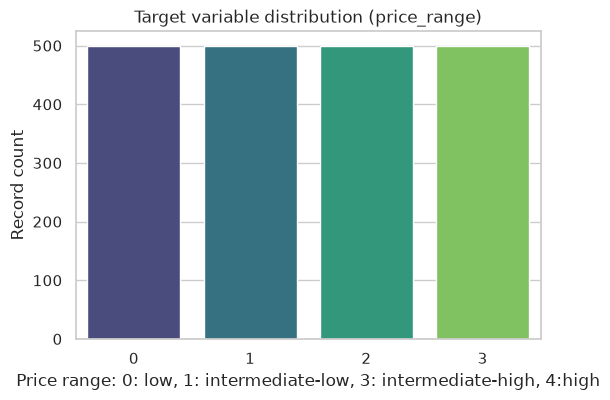

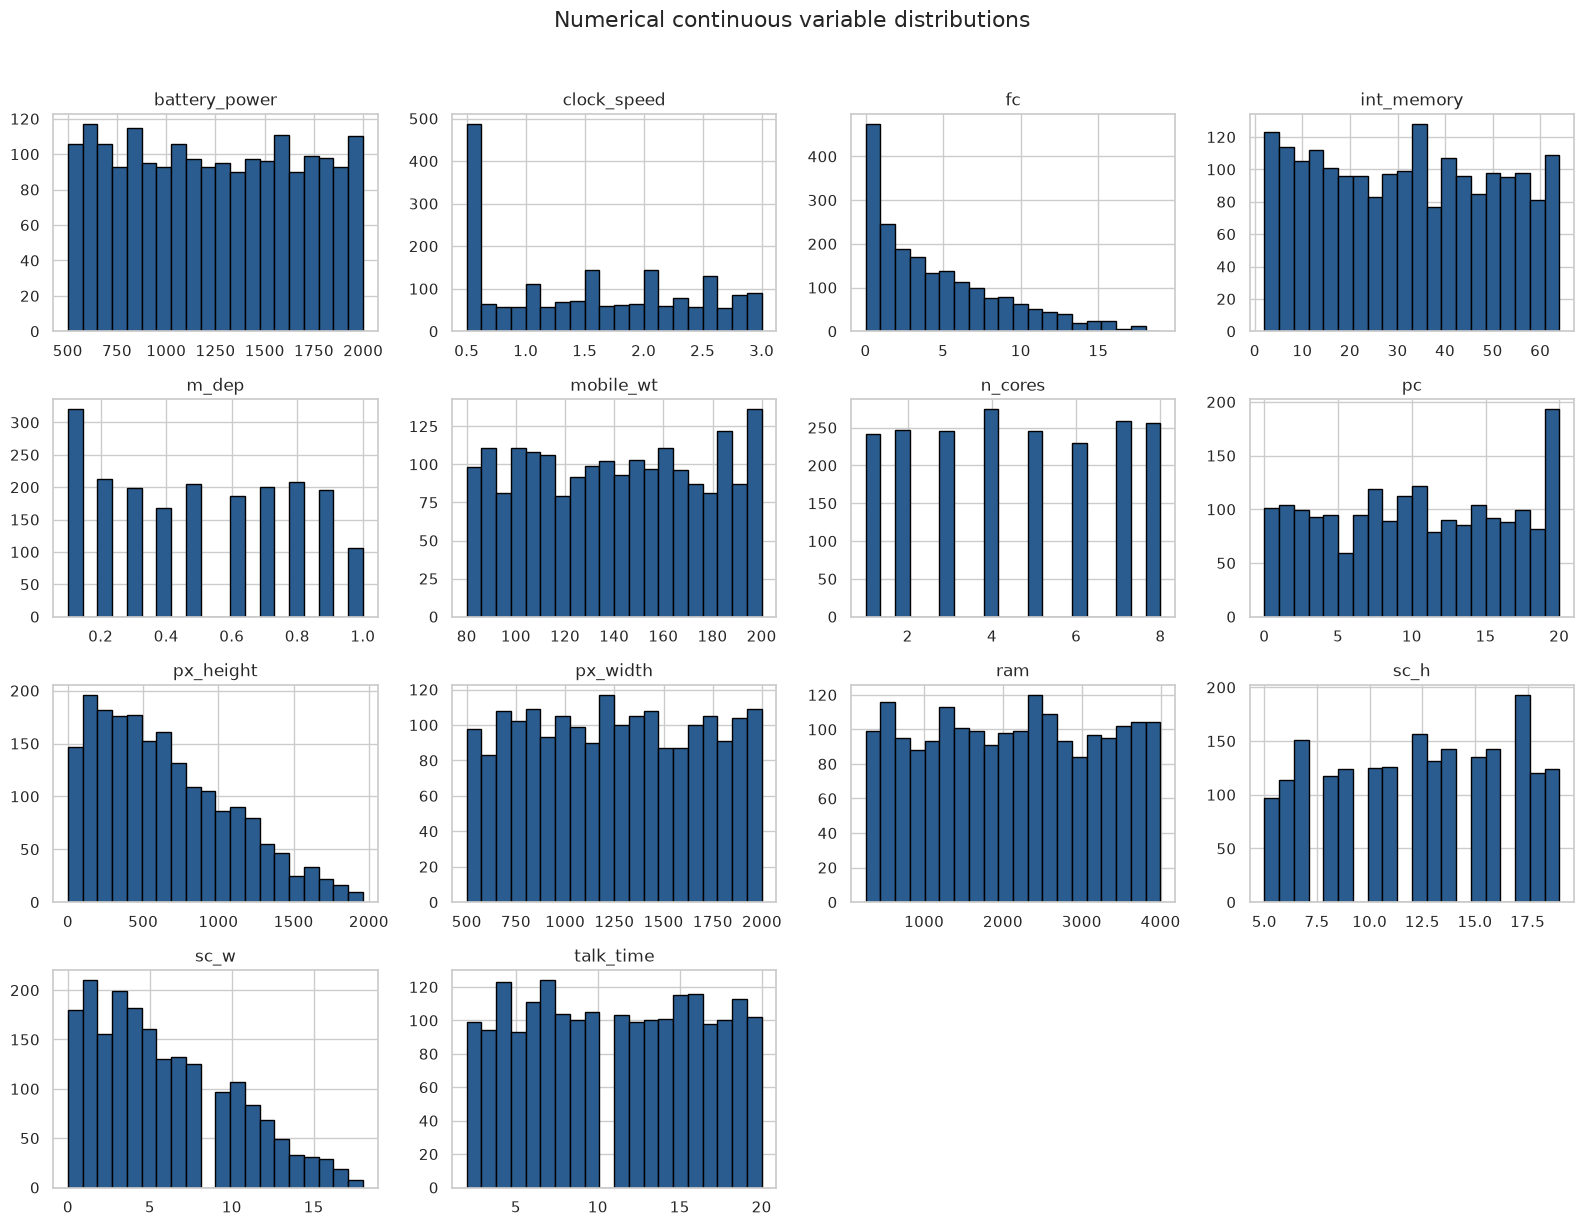


 Correlations
Correlation with price_range: 
 price_range      1.000000
ram              0.917046
battery_power    0.200723
px_width         0.165818
px_height        0.148858
int_memory       0.044435
sc_w             0.038711
pc               0.033599
three_g          0.023611
sc_h             0.022986
fc               0.021998
talk_time        0.021859
blue             0.020573
wifi             0.018785
dual_sim         0.017444
four_g           0.014772
n_cores          0.004399
m_dep            0.000853
clock_speed     -0.006606
mobile_wt       -0.030302
touch_screen    -0.030411
Name: price_range, dtype: float64


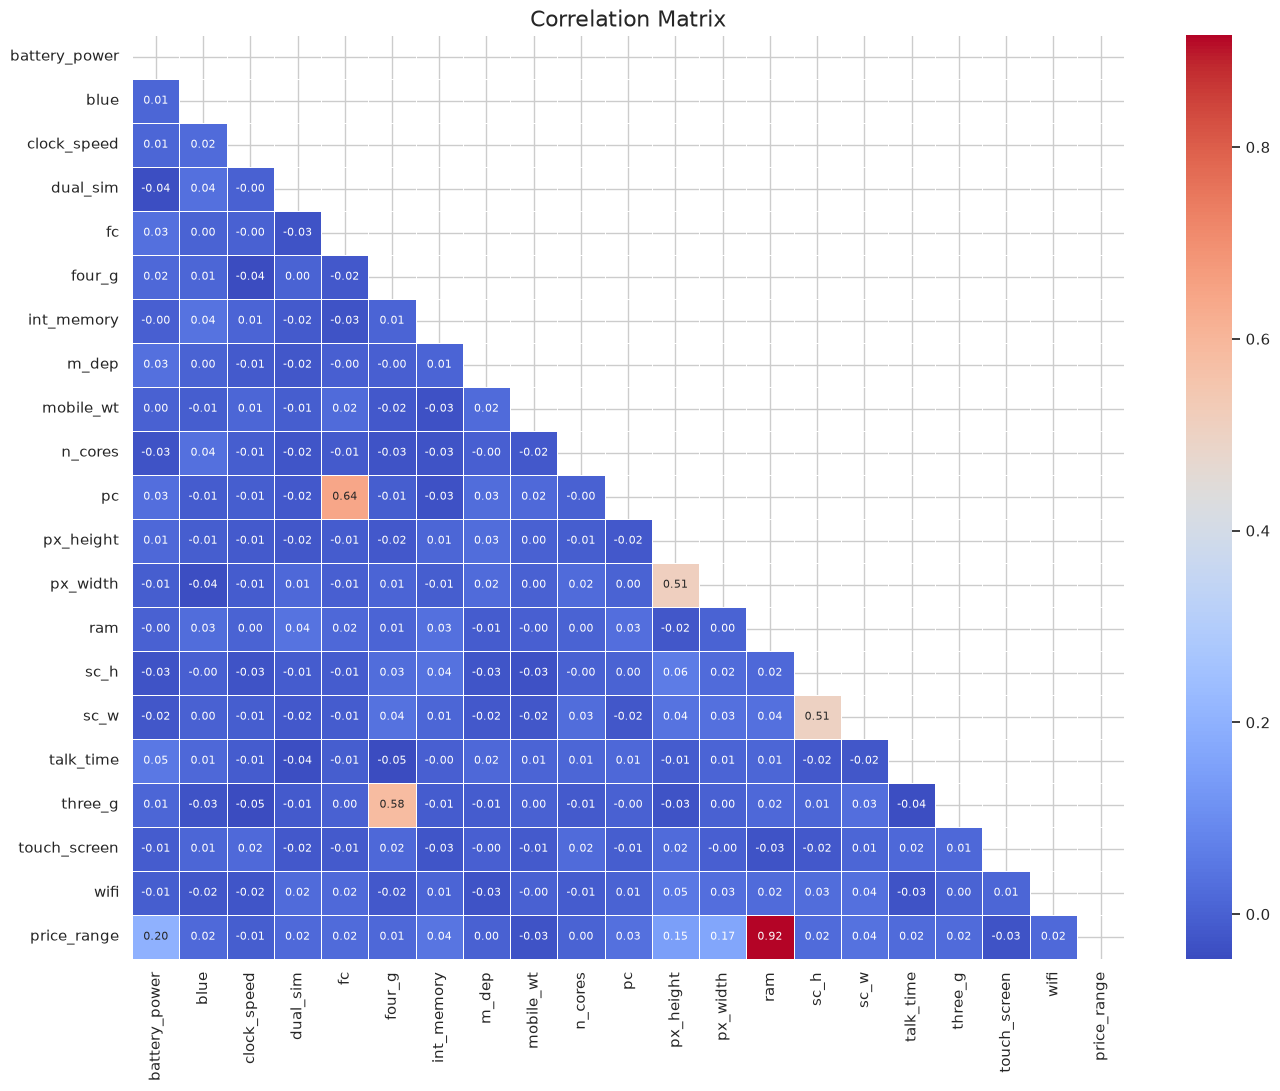


 IQR outlier detection method
Outlier quantity per column (following 1.5 * IQR):
 - fc: 18 outliers
 - px_height: 2 outliers


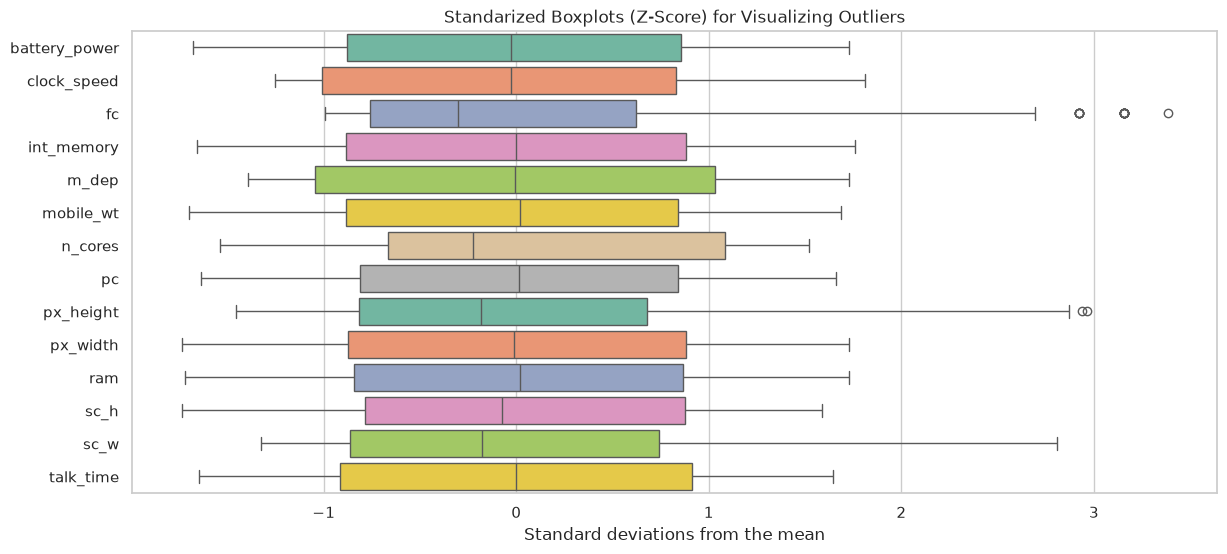


 Potential wrong data (unrealistic 0s))
 - Height screen pixels (px_height == 0): 2
 - Width screen in cms (sc_w == 0): 180


In [40]:
# Visual seaborn definition
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print(f"Loaded dataset: {df.shape[0]} rows and {df.shape[1]} columns.\n")

print("Null and duplicated values and data types")
print("\nNull values per column:\n", df.isna().sum())
print("\nDuplicated rows:", df.duplicated().sum())
print("\nData types:\n", df.dtypes.value_counts())

# Distributions
print("\n Distributions")
# Distribución de la variable objetivo (price_range)
plt.figure(figsize=(6, 4))
sns.countplot(x="price_range", data=df, palette="viridis")
plt.title("Target variable distribution (price_range)")
plt.xlabel("Price range: 0: low, 1: intermediate-low, 2: intermediate-high, 3:high")
plt.ylabel("Record count")
plt.show()

# Splitting variables in binary, numerical and categorical columns
binary_cols = [col for col in df.columns if df[col].nunique() == 2]
num_cols = [col for col in df.columns if col not in binary_cols and col != "price_range"]
cat_cols = [col for col in df.columns if col not in [binary_cols,num_cols]]

# Histogramas para variables numéricas continuas
df[num_cols].hist(bins=20, figsize=(16, 12), layout=(4, 4), color="#2b5c8f", edgecolor="black")
plt.suptitle("Numerical continuous variable distributions", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

# Correlations
print("\n Correlations")
corr_matrix = df.corr()

# Top correlations with price_range
target_corr = corr_matrix["price_range"].sort_values(ascending=False)
print("Correlation with price_range: \n", target_corr)

# Correlations Heatmap
plt.figure(figsize=(16, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5, annot_kws={"size": 8})
plt.title("Correlation Matrix", fontsize=16)
plt.show()

# Outliers
print("\n IQR outlier detection method")
outlier_summary = {}

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    if len(outliers) > 0:
        outlier_summary[col] = len(outliers)

print("Outlier quantity per column (following 1.5 * IQR):")
for col, count in outlier_summary.items():
    print(f" - {col}: {count} outliers")

# Numerical columns standarization  (mean = 0, std = 1)
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df[num_cols]), columns=num_cols)

# Boxplots de variables numéricas estandarizadas para comparar escalas y outliers
df_scaled = (df[num_cols] - df[num_cols].mean()) / df[num_cols].std()
plt.figure(figsize=(14, 6))
sns.boxplot(data=df_scaled, orient="h", palette="Set2")
plt.title("Standarized Boxplots (Z-Score) for Visualizing Outliers")
plt.xlabel("Standard deviations from the mean")
plt.show()

# Potential wrong data (unrealistic 0s))
print("\n Potential wrong data (unrealistic 0s))")
print(" - Height screen pixels (px_height == 0):", (df["px_height"] == 0).sum())
print(" - Width screen in cms (sc_w == 0):", (df["sc_w"] == 0).sum())

In [43]:
def preprocessing(df: pd.DataFrame) -> pd.DataFrame:
    """Removes rows containing anomalous zero values and statistical outliers.

    This function filters the dataset by performing two cleaning steps:
    1. Drops rows with physically impossible zero values in screen dimensions
       (`px_height` and `sc_w`).
    2. Drops rows containing statistical outliers in continuous numerical columns
       using the Interquartile Range (1.5 * IQR) rule.

    Args:
        df (pd.DataFrame): Raw input DataFrame containing mobile phone features
            (e.g., `train.csv`).

    Returns:
        pd.DataFrame: A filtered copy of the input DataFrame with anomalous rows
            removed and a reset index.
    """
    df_clean = df.copy()
    initial_rows = len(df_clean)

    # Drop rows with physical zero anomalies in screen dimensions
    zero_anomaly_cols = ["px_height", "sc_w"]
    for col in zero_anomaly_cols:
        if col in df_clean.columns:
            df_clean = df_clean[df_clean[col] > 0]

    # Drop rows with statistical outliers using the 1.5 * IQR rule
    exclude_cols = {"price_range", "id"}
    num_cols = [
        col for col in df_clean.select_dtypes(include=[np.number]).columns
        if df_clean[col].nunique() > 2 and col not in exclude_cols
    ]

    # Build a combined boolean mask across all continuous columns
    valid_mask = pd.Series(True, index=df_clean.index)
    for col in num_cols:
        Q1 = df_clean[col].quantile(0.25)
        Q3 = df_clean[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        valid_mask &= (df_clean[col] >= lower_bound) & (df_clean[col] <= upper_bound)

    df_clean = df_clean[valid_mask].reset_index(drop=True)

    print(f"Rows removed: {initial_rows - len(df_clean)} | Remaining rows: {len(df_clean)}")
    return df_clean


In [48]:
df_clean = preprocessing(df)

Rows removed: 200 | Remaining rows: 1800


In [49]:
df_clean.head(3)

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2


No feature engineering because
• No categorical encoding needed

# Modeling

In [57]:

# TRAIN / VALIDATION / TEST SPLIT (80% / 10% / 10%)
X = df_clean.drop(columns=["price_range"])
y = df_clean["price_range"]

# First split: 90% Train+Val, 10% Hold-out Test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.10, random_state=42, stratify=y
)

# Second split: Split the 90% into 80% Train and 10% Validation (1/9 ≈ 0.1111)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=(1 / 9), random_state=42, stratify=y_train_val
)

print(f"Split shapes -> Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}\n")

summary_rows = []
final_models = {}
# BASELINE MODEL: SHALLOW DECISION TREE (max_depth=3) (Fit on Train, Evaluate on Val & Test)
baseline_pipe = Pipeline([
    ("clf", DecisionTreeClassifier(max_depth=3, random_state=42))
])

baseline_pipe.fit(X_train, y_train)
final_models["Baseline (Shallow Tree)"] = baseline_pipe

val_auc_base = roc_auc_score(y_val, baseline_pipe.predict_proba(X_val), multi_class="ovr")
test_probs_base = baseline_pipe.predict_proba(X_test)
test_preds_base = baseline_pipe.predict(X_test)
summary_rows.append({
    "Model": "Baseline (Shallow Tree)",
    "Best Hyperparameters": "max_depth=3",
    "Val AUC-ROC": val_auc_base,
    "Test AUC-ROC": roc_auc_score(y_test, test_probs_base, multi_class="ovr"),
    "Test Accuracy": accuracy_score(y_test, test_preds_base)
})


# HYPERPARAMETER OPTIMIZATION (FIT ON TRAIN, TUNE ON VAL)
models_and_grids = {
    "Support Vector Machine (SVC)": {
        "pipeline": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(probability=True, random_state=42))
        ]),
        "params": {
            "clf__C": list((0.1, 1, 10, 50)),
            "clf__kernel": list(("linear", "rbf")),
            "clf__gamma": list(("scale", "auto"))
        }
    },
    "Random Forest": {
        "pipeline": Pipeline([
            ("clf", RandomForestClassifier(random_state=42))
        ]),
        "params": {
            "clf__n_estimators": list((100, 200, 300)),
            "clf__max_depth": list((None, 10, 20)),
            "clf__min_samples_split": list((2, 5))
        }
    },
    "Gradient Boosting": {
        "pipeline": Pipeline([
            ("clf", GradientBoostingClassifier(random_state=42))
        ]),
        "params": {
            "clf__n_estimators": list((100, 200)),
            "clf__learning_rate": list((0.05, 0.1)),
            "clf__max_depth": list((3, 5))
        }
    }
}

for model_name, config in models_and_grids.items():
    best_val_auc = -1.0
    best_params = None
    best_estimator = None

    # Search over every hyperparameter combination: fit on Train, score on Val
    for params in ParameterGrid(config["params"]):
        candidate = clone(config["pipeline"]).set_params(**params)
        candidate.fit(X_train, y_train)
        
        val_probs = candidate.predict_proba(X_val)
        val_auc = roc_auc_score(y_val, val_probs, multi_class="ovr")
        
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_params = params
            best_estimator = candidate

    final_models[model_name] = best_estimator

    # Evaluate the best-tuned version of this model on the untouched Test set
    test_probs = best_estimator.predict_proba(X_test)
    test_preds = best_estimator.predict(X_test)

    summary_rows.append({
        "Model": model_name,
        "Best Hyperparameters": str(best_params),
        "Val AUC-ROC": best_val_auc,
        "Test AUC-ROC": roc_auc_score(y_test, test_probs, multi_class="ovr"),
        "Test Accuracy": accuracy_score(y_test, test_preds)
    })

# FINAL COMPARISON TABLE & BEST MODEL CONCLUSION
summary_df = pd.DataFrame(summary_rows).sort_values(by="Test AUC-ROC", ascending=False).reset_index(drop=True)
print("FINAL MODEL COMPARISON SUMMARY")
display(summary_df)  # Use print(summary_df.to_string()) if not in Jupyter

winner_name = summary_df.loc[0, "Model"]
winner_model = final_models[winner_name]

print(f"\nConclusion -> Overall Best Model: {winner_name}")
print(f"Test AUC-ROC: {summary_df.loc[0, 'Test AUC-ROC']:.4f} | Test Accuracy: {summary_df.loc[0, 'Test Accuracy']:.4f}\n")
print("Detailed Classification Report on Test Set (Winning Model):")
print(classification_report(y_test, winner_model.predict(X_test)))


Split shapes -> Train: (1440, 20) | Val: (180, 20) | Test: (180, 20)



/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1

FINAL MODEL COMPARISON SUMMARY


,Model,Best Hyperparameters,Val AUC-ROC,Test AUC-ROC,Test Accuracy
0,Support Vector Machine (SVC),"{'clf__C': 1, 'clf__gamma': 'scale', 'clf__ker...",0.996914,1.000000,0.988889
1,Gradient Boosting,"{'clf__learning_rate': 0.1, 'clf__max_depth': ...",0.981152,0.994239,0.933333
2,Random Forest,"{'clf__max_depth': None, 'clf__min_samples_spl...",0.970864,0.988374,0.933333
3,Baseline (Shallow Tree),max_depth=3,0.888477,0.926955,0.794444



Conclusion -> Overall Best Model: Support Vector Machine (SVC)
Test AUC-ROC: 1.0000 | Test Accuracy: 0.9889

Detailed Classification Report on Test Set (Winning Model):
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        45
           1       1.00      0.96      0.98        45
           2       1.00      1.00      1.00        45
           3       1.00      1.00      1.00        45

    accuracy                           0.99       180
   macro avg       0.99      0.99      0.99       180
weighted avg       0.99      0.99      0.99       180

